# Pagerintų modelių palyginimas

Tas pats užšaldytas skaidymas. Nauji modeliai naudoja log1p, chemijos santykius, dublikatų ir kraštų svorius bei monotoninius apribojimus.

CatBoost asimetrinis stipriau baudžia žemo balo pervertinimą. CatBoost ir LightGBM ordinaliniai modeliai turi vieną ansamblį visiems Frank–Hall slenksčiams.

In [1]:
from pathlib import Path
import sys
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "winequality").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CANDIDATES = [
    ROOT / "results" / "pagerinta",
    ROOT / "results" / "palyginimas",
    ROOT / "results",
    ROOT / "results" / "smoke",
]
RESULTS = next(path for path in CANDIDATES if (path / "comparison.csv").exists())
ORDER = ["mean", "linear", "cat_asym", "cat_ordinal", "lgbm_ordinal"]
LABELS = {
    "mean": "Vidurkis",
    "linear": "Tiesinė, nauji požymiai",
    "cat_asym": "CatBoost asimetrinis",
    "cat_ordinal": "CatBoost ordinalinis",
    "lgbm_ordinal": "LightGBM ordinalinis",
    "xgb_ordinal": "XGBOrdinal (ankstesnis)",
    "catboost": "CatBoost (ankstesnis)",
}
WINE = {"red": "raudonas", "white": "baltas"}
COLORS = {
    "mean": "#7f7f7f",
    "linear": "#4c78a8",
    "cat_asym": "#e45756",
    "cat_ordinal": "#54a24b",
    "lgbm_ordinal": "#f58518",
    "xgb_ordinal": "#b279a2",
    "catboost": "#9d755d",
}
PREVIOUS_PATH = ROOT / "results" / "palyginimas" / "comparison.csv"
PREVIOUS_METRICS_PATH = ROOT / "results" / "palyginimas" / "metrics.json"
previous = pd.read_csv(PREVIOUS_PATH) if PREVIOUS_PATH.exists() else None
previous_metrics = json.loads(PREVIOUS_METRICS_PATH.read_text(encoding="utf-8")) if PREVIOUS_METRICS_PATH.exists() else None
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

comparison = pd.read_csv(RESULTS / "comparison.csv")
metrics = json.loads((RESULTS / "metrics.json").read_text(encoding="utf-8"))
comparison["model"] = pd.Categorical(comparison["model"], ORDER, ordered=True)
comparison = comparison.sort_values(["wine", "model"]).reset_index(drop=True)
print("Rezultatai:", RESULTS)
print("Protokolas:", metrics.get("protocol"), "| pasirinktas modelis:", metrics.get("selected_model"))

Rezultatai: C:\Users\marci\Desktop\uni stuff\Magistras\1 sem\IS\IS_Egzaminas\results\pagerinta
Protokolas: pagerinta | pasirinktas modelis: lgbm_ordinal


## Bendra palyginimo lentelė

In [2]:
columns = ["wine", "model", "mae", "mae_rounded", "rmse", "acc_0.5", "acc_1.0", "kappa_w", "macro_f1", "log_loss", "brier"]
table = comparison[columns].copy()
table["wine"] = table["wine"].map(WINE)
table["model"] = table["model"].astype(str).map(LABELS)
table = table.rename(columns={
    "wine": "Vynas",
    "model": "Modelis",
    "mae": "MAE",
    "mae_rounded": "MAE (sveikasis)",
    "rmse": "RMSE",
    "acc_0.5": "Acc 0,5",
    "acc_1.0": "Acc 1,0",
    "kappa_w": "κw",
    "macro_f1": "Makro-F1",
    "log_loss": "Log-loss",
    "brier": "Brier",
})
table.round(4)

,Vynas,Modelis,MAE,MAE (sveikasis),RMSE,"Acc 0,5","Acc 1,0",κw,Makro-F1,Log-loss,Brier
0,raudonas,Vidurkis,0.6837,0.6562,0.8090,0.4000,0.8250,0.0000,0.3014,NaN,NaN
1,raudonas,"Tiesinė, nauji požymiai",0.4897,0.4125,0.6256,0.6219,0.8812,0.5473,0.5231,NaN,NaN
2,raudonas,CatBoost asimetrinis,0.4765,0.4000,0.6381,0.6219,0.8844,0.5956,0.5291,NaN,NaN
3,raudonas,CatBoost ordinalinis,0.4717,0.3906,0.5998,0.6281,0.9031,0.6170,0.5441,0.9061,0.5057
4,raudonas,LightGBM ordinalinis,0.4631,0.4062,0.6106,0.6062,0.8938,0.6289,0.5658,0.9686,0.5237
5,baltas,Vidurkis,0.6734,0.6333,0.8919,0.4484,0.7457,0.0000,0.2848,NaN,NaN
6,baltas,"Tiesinė, nauji požymiai",0.5784,0.5260,0.7818,0.5230,0.8509,0.4578,0.4694,NaN,NaN
7,baltas,CatBoost asimetrinis,0.5301,0.4740,0.7170,0.5649,0.8355,0.5479,0.5352,NaN,NaN
8,baltas,CatBoost ordinalinis,0.5463,0.4780,0.6946,0.5536,0.8641,0.5740,0.5430,1.0260,0.5694
9,baltas,LightGBM ordinalinis,0.5403,0.4801,0.6917,0.5628,0.8703,0.5587,0.5494,1.0398,0.5737


## MAE ir κw pagal vyno tipą

In [3]:
def pivot(metric, title):
    wide = comparison.pivot(index="model", columns="wine", values=metric).reindex(ORDER)
    wide.index = [LABELS[name] for name in wide.index]
    wide = wide.rename(columns=WINE)
    wide.columns.name = None
    wide.index.name = title
    return wide.round(4)

mae_table = pivot("mae", "MAE")
kappa_table = pivot("kappa_w", "κw")
f1_table = pivot("macro_f1", "Makro-F1")
display(mae_table)
display(kappa_table)
display(f1_table)

,raudonas,baltas
MAE,,
Vidurkis,0.6837,0.6734
"Tiesinė, nauji požymiai",0.4897,0.5784
CatBoost asimetrinis,0.4765,0.5301
CatBoost ordinalinis,0.4717,0.5463
LightGBM ordinalinis,0.4631,0.5403


,raudonas,baltas
κw,,
Vidurkis,0.0000,0.0000
"Tiesinė, nauji požymiai",0.5473,0.4578
CatBoost asimetrinis,0.5956,0.5479
CatBoost ordinalinis,0.6170,0.5740
LightGBM ordinalinis,0.6289,0.5587


,raudonas,baltas
Makro-F1,,
Vidurkis,0.3014,0.2848
"Tiesinė, nauji požymiai",0.5231,0.4694
CatBoost asimetrinis,0.5291,0.5352
CatBoost ordinalinis,0.5441,0.5430
LightGBM ordinalinis,0.5658,0.5494


## MAE grafikas

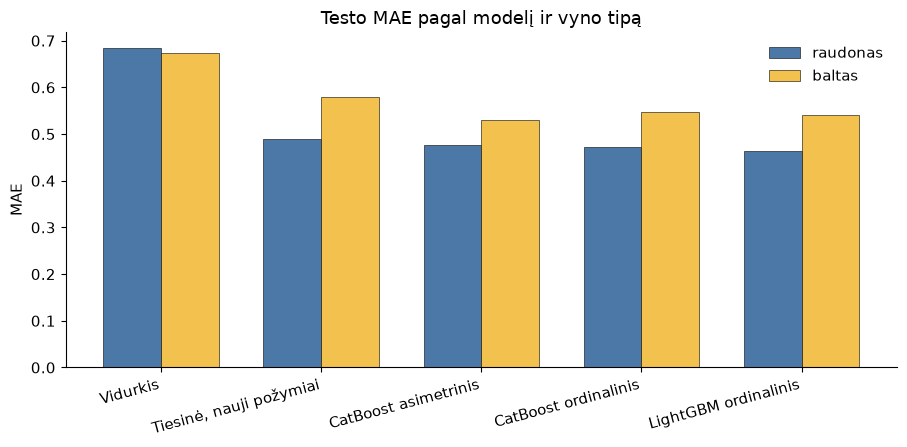

In [4]:
def grouped_bars(metric, ylabel, title):
    wines = [wine for wine in ["red", "white"] if wine in set(comparison["wine"])]
    fig, ax = plt.subplots(figsize=(9.2, 4.6))
    x = np.arange(len(ORDER))
    width = 0.36 if len(wines) > 1 else 0.55
    for i, wine in enumerate(wines):
        part = comparison[comparison["wine"] == wine].set_index("model").reindex(ORDER)
        offset = (i - (len(wines) - 1) / 2) * width
        ax.bar(x + offset, part[metric], width=width, label=WINE[wine], color=["#4c78a8", "#f2c14e"][i], edgecolor="black", linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[name] for name in ORDER], rotation=15, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    return fig

grouped_bars("mae", "MAE", "Testo MAE pagal modelį ir vyno tipą")
plt.show()

## κw ir makro-F1

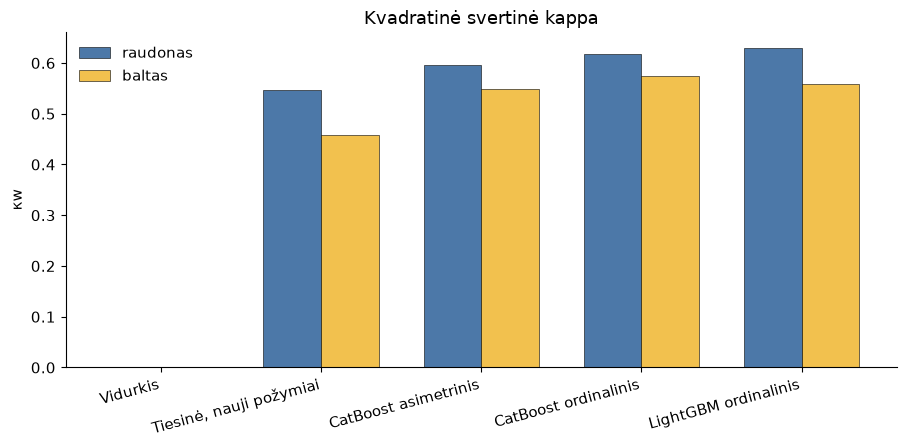

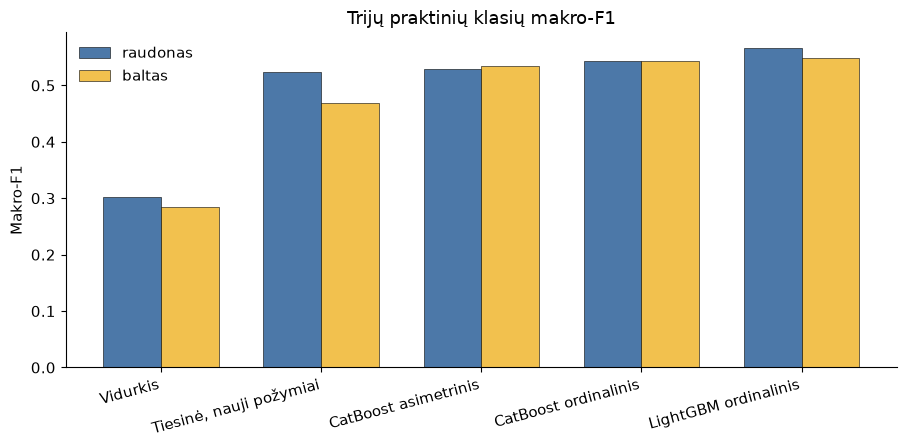

In [5]:
grouped_bars("kappa_w", "κw", "Kvadratinė svertinė kappa")
plt.show()
grouped_bars("macro_f1", "Makro-F1", "Trijų praktinių klasių makro-F1")
plt.show()

## Pokytis nuo ankstesnio CatBoost ir XGBOrdinal

In [6]:
rows = []
wines = [wine for wine in ["red", "white"] if wine in set(comparison["wine"].astype(str))]
for wine in wines:
    for name in ORDER:
        part = comparison[(comparison["wine"] == wine) & (comparison["model"].astype(str) == name)].iloc[0]
        rows.append({"Vynas": WINE[wine], "Modelis": LABELS[name], "MAE": part["mae"], "κw": part["kappa_w"], "variantas": "pagerintas"})
    if previous is not None:
        for name in ["catboost", "xgb_ordinal"]:
            part = previous[(previous["wine"] == wine) & (previous["model"] == name)]
            if part.empty:
                continue
            item = part.iloc[0]
            rows.append({"Vynas": WINE[wine], "Modelis": LABELS[name], "MAE": item["mae"], "κw": item["kappa_w"], "variantas": "ankstesnis"})
delta = pd.DataFrame(rows)
delta.round(4)

,Vynas,Modelis,MAE,κw,variantas
0,raudonas,Vidurkis,0.6837,0.0000,pagerintas
1,raudonas,"Tiesinė, nauji požymiai",0.4897,0.5473,pagerintas
2,raudonas,CatBoost asimetrinis,0.4765,0.5956,pagerintas
3,raudonas,CatBoost ordinalinis,0.4717,0.6170,pagerintas
4,raudonas,LightGBM ordinalinis,0.4631,0.6289,pagerintas
5,raudonas,CatBoost (ankstesnis),0.4507,0.5899,ankstesnis
6,raudonas,XGBOrdinal (ankstesnis),0.4638,0.6251,ankstesnis
7,baltas,Vidurkis,0.6734,0.0000,pagerintas
8,baltas,"Tiesinė, nauji požymiai",0.5784,0.4578,pagerintas
9,baltas,CatBoost asimetrinis,0.5301,0.5479,pagerintas


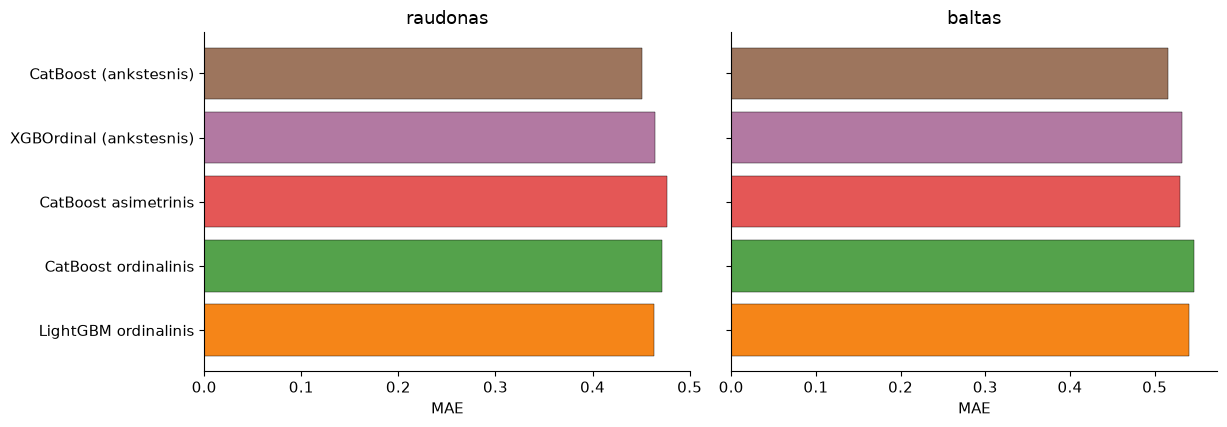

In [7]:
if previous is not None:
    fig, axes = plt.subplots(1, len(wines), figsize=(6.2 * len(wines), 4.4), sharey=True)
    if len(wines) == 1:
        axes = [axes]
    show = ["catboost", "xgb_ordinal", "cat_asym", "cat_ordinal", "lgbm_ordinal"]
    for ax, wine in zip(axes, wines):
        heights = []
        labels = []
        colors = []
        for name in show:
            source = comparison if name in ORDER else previous
            part = source[(source["wine"] == wine) & (source["model"].astype(str) == name)]
            if part.empty:
                continue
            heights.append(float(part.iloc[0]["mae"]))
            labels.append(LABELS[name])
            colors.append(COLORS[name])
        ax.barh(labels[::-1], heights[::-1], color=colors[::-1], edgecolor="black", linewidth=0.3)
        ax.set_xlabel("MAE")
        ax.set_title(WINE[wine])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
    fig.tight_layout()
    plt.show()